FIRST LETS EXTRACT THE ZIPFILE(AS I UPLOADED AS ZIP FILE)

In [4]:
import zipfile
import os

zip_path = '/content/archive.zip'
extract_path = '/content/cars_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


LETS FIND FILES DETAILS

In [6]:
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/cars_dataset/UsedCars_Kolkata.csv
/content/cars_dataset/Dataset.csv
/content/cars_dataset/UsedCars_Combined.csv
/content/cars_dataset/UsedCars_Hyderabad.csv
/content/cars_dataset/UsedCars_Banglore.csv
/content/cars_dataset/UsedCars_Chennai.csv
/content/cars_dataset/UsedCars_Delhi.csv
/content/cars_dataset/UsedCars_Pune.csv
/content/cars_dataset/UsedCars_Mumbai.csv


WE GONNA LOAD THE COMBINED DATASET

In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/cars_dataset/UsedCars_Combined.csv')

print("Dataset has been loaded successfully")
print("Shape :", df.shape)

df.head()

Dataset has been loaded successfully
Shape : (1725, 9)


,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
0,0,2016,Honda,Honda Brio S MT,Brio,425000.0,9680.0,Petrol,Mumbai
1,1,2012,Nissan,Nissan Sunny XV Diesel,Sunny,325000.0,119120.0,Diesel,Mumbai
2,2,2017,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,2650000.0,64593.0,Diesel,Thane
3,3,2017,Mercedes-Benz,Mercedes-Benz E-Class E 220d Expression [2019-...,E-Class,4195000.0,25000.0,Diesel,Mumbai
4,4,2012,Hyundai,Hyundai Verna Fluidic 1.6 CRDi SX,Verna,475000.0,23800.0,Diesel,Mumbai


AM GONNA SEE WHATS INSIDE DATASET

In [8]:
print("Dataset's Information:")
df.info()

print("\nColumn Names:\n")
print(df.columns.tolist())

print("\nStatistical Summary:")
df.describe(include='all')

Dataset's Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1725 entries, 0 to 1724
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Id                       1725 non-null   int64  
 1   year                     1725 non-null   int64  
 2   brand                    1725 non-null   object 
 3   full_model_name          1725 non-null   object 
 4   model_name               1725 non-null   object 
 5   price                    1725 non-null   float64
 6   distance_travelled(kms)  1725 non-null   float64
 7   fuel_type                1725 non-null   object 
 8   city                     1725 non-null   object 
dtypes: float64(2), int64(2), object(5)
memory usage: 121.4+ KB

Column Names:

['Id', 'year', 'brand', 'full_model_name', 'model_name', 'price', 'distance_travelled(kms)', 'fuel_type', 'city']

Statistical Summary:


,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
count,1725.000000,1725.000000,1725,1725,1725,1.725000e+03,1725.000000,1725,1725
unique,NaN,NaN,31,750,169,NaN,NaN,5,15
top,NaN,NaN,Hyundai,Ford EcoSport Titanium 1.5L TDCi,Creta,NaN,NaN,Diesel,Chennai
freq,NaN,NaN,297,12,71,NaN,NaN,922,493
mean,862.000000,2015.390725,NaN,NaN,NaN,1.494837e+06,53848.256232,NaN,NaN
std,498.108924,3.207504,NaN,NaN,NaN,1.671658e+06,44725.541963,NaN,NaN
min,0.000000,1990.000000,NaN,NaN,NaN,6.250000e+04,350.000000,NaN,NaN
25%,431.000000,2013.000000,NaN,NaN,NaN,5.450000e+05,29000.000000,NaN,NaN
50%,862.000000,2016.000000,NaN,NaN,NaN,8.750000e+05,49000.000000,NaN,NaN
75%,1293.000000,2018.000000,NaN,NaN,NaN,1.825000e+06,70500.000000,NaN,NaN


GONNA CHECK THE DATSET QUALITY OF MISSING VALUES AND DUPLICATE ROWS

In [9]:
print("Missing Values :")
print(df.isnull().sum())

print("\nDuplicate Rows :")
print(df.duplicated().sum())

Missing Values :
Id                         0
year                       0
brand                      0
full_model_name            0
model_name                 0
price                      0
distance_travelled(kms)    0
fuel_type                  0
city                       0
dtype: int64

Duplicate Rows :
0


LETS CHECK THE DATATYPES AND UNIQUE VAL IN THE COLUMS TO UNDERSTAND THE COLUMNS

In [10]:
print(df.dtypes)

print("\nFuel Types:")
print(df['fuel_type'].value_counts())

print("\nCities:")
print(df['city'].value_counts())

print("\nCar Brands:")
print(df['brand'].value_counts().head(15))

print("\nManufacturing Years:")
print(df['year'].describe())

print("\nPrice Details:")
print(df['price'].describe())

print("\nDistance Travelled:")
print(df['distance_travelled(kms)'].describe())

Id                           int64
year                         int64
brand                       object
full_model_name             object
model_name                  object
price                      float64
distance_travelled(kms)    float64
fuel_type                   object
city                        object
dtype: object

Fuel Types:
fuel_type
Diesel        922
Petrol        788
CNG + 1         8
Petrol + 1      6
Hybrid          1
Name: count, dtype: int64

Cities:
city
Chennai        493
Bangalore      247
Pune           247
Hyderabad      245
Delhi          187
Mumbai         165
Dehradun        56
Thane           48
Noida           12
Ghaziabad       10
Lucknow          6
Navi Mumbai      5
Faridabad        2
Agra             1
Panchkula        1
Name: count, dtype: int64

Car Brands:
brand
Hyundai          297
Maruti Suzuki    275
Honda            153
Mercedes-Benz    131
Toyota           117
BMW              111
Audi              98
Mahindra          93
Ford              78

CHECKING FOR UNUSUAL VALUES INIT

In [11]:
print("Minimum Year:", df['year'].min())
print("Maximum Year:", df['year'].max())

print("Minimum Price:", df['price'].min())
print("Maximum Price:", df['price'].max())

print("Minimum Distance:", df['distance_travelled(kms)'].min())
print("Maximum Distance:", df['distance_travelled(kms)'].max())

Minimum Year: 1990
Maximum Year: 2021
Minimum Price: 62500.0
Maximum Price: 14700000.0
Minimum Distance: 350.0
Maximum Distance: 790000.0


INVESTIGATING UNUSUAL VALUES

In [12]:
print("Top 10 Expensive Cars:")
display(df.nlargest(10, 'price'))

print("\nTop 10 Cheapest Cars:")
display(df.nsmallest(10, 'price'))

print("\nHighest Distance Travelled:")
display(df.nlargest(10, 'distance_travelled(kms)'))

print("\nOldest Cars:")
display(df.nsmallest(10, 'year'))

Top 10 Expensive Cars:


,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
376,376,2018,Land Rover,Land Rover Range Rover 3.0 V6 Diesel Vogue,3.0,14700000.0,25000.0,Diesel,Delhi
377,377,2018,Toyota,Toyota Land Cruiser LC 200 VX,Land,14500000.0,90000.0,Diesel,Delhi
806,806,2015,Mercedes-Benz,Mercedes-Benz G-Class G 63 AMG,G-Class,14000000.0,23000.0,Petrol,Hyderabad
1537,1537,2015,Mercedes-Benz,Mercedes-Benz S-Class S 63 AMG,S-Class,13000000.0,13000.0,Petrol,Pune
68,68,2012,Lamborghini,Lamborghini Gallardo India Ltd Edition LP 550-2,Gallardo,12500000.0,14500.0,Petrol,Dehradun
311,311,2012,Lamborghini,Lamborghini Gallardo India Ltd Edition LP 550-2,Gallardo,12500000.0,14500.0,Petrol,Dehradun
405,405,2019,Land Rover,Land Rover Range Rover Sport SE 3.0 Diesel [20...,Sport,12300000.0,17000.0,Diesel,Delhi
366,366,2020,BMW,BMW 7 Series 740Li DPE Signature,7,12100000.0,12000.0,Petrol,Delhi
355,355,2020,BMW,BMW X7 xDrive30d DPE Signature [2019-2020],X7,11500000.0,12000.0,Diesel,Delhi
1671,1671,2020,BMW,BMW 7 Series 730Ld DPE Signature,7,11500000.0,9000.0,Diesel,Pune



Top 10 Cheapest Cars:


,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
272,272,2007,Maruti Suzuki,Maruti Suzuki Wagon R LXi Minor,Wagon,62500.0,75000.0,Petrol,Delhi
281,281,2012,Tata,Tata Nano Base,Nano,65000.0,18000.0,Petrol,Ghaziabad
1006,1006,2010,Tata,Tata Nano LX,Nano,80000.0,10001.0,Petrol,Chennai
1252,1252,2010,Tata,Tata Nano LX,Nano,80000.0,10001.0,Petrol,Chennai
965,965,2012,Tata,Tata Nano LX,Nano,95000.0,31000.0,Petrol,Hyderabad
1681,1681,2011,Tata,Tata Nano LX,Nano,95000.0,48405.0,Petrol,Pune
1616,1616,2007,Hyundai,Hyundai Santro Xing XL eRLX - Euro III,Santro,110000.0,87000.0,Petrol,Pune
117,117,2010,Chevrolet,Chevrolet Beat LT Petrol,Beat,115000.0,82000.0,Petrol,Mumbai
438,438,2010,Maruti Suzuki,Maruti Suzuki Wagon R 1.0 LXi,Wagon,125000.0,71000.0,Petrol,Delhi
451,451,2009,Maruti Suzuki,Maruti Suzuki Wagon R LXi Minor,Wagon,135000.0,75000.0,Petrol,Delhi



Highest Distance Travelled:


,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
257,257,2015,Toyota,Toyota Innova 2.5 G BS IV 7 STR,Innova,925000.0,790000.0,Diesel,Delhi
260,260,2011,Mahindra,Mahindra Scorpio VLX 4WD Airbag BS-IV,Scorpio,465000.0,720000.0,Diesel,Delhi
883,883,2015,Audi,Audi Q5 3.0 TDI quattro Premium Plus,Q5,2850000.0,550000.0,Diesel,Hyderabad
1596,1596,2013,Hyundai,Hyundai i10 Sportz 1.2 Kappa2,i10,340000.0,508881.0,Petrol,Pune
1205,1205,2017,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,2800000.0,420000.0,Diesel,Chennai
1452,1452,2017,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,2800000.0,420000.0,Diesel,Chennai
742,742,2004,Toyota,Toyota Qualis GS G1,Qualis,240000.0,209616.0,Diesel,Hyderabad
877,877,2004,Toyota,Toyota Qualis GS G1,Qualis,240000.0,209616.0,Diesel,Hyderabad
709,709,2005,Toyota,Toyota Innova 2.5 G4 8 STR,Innova,550000.0,202000.0,Diesel,Bangalore
229,229,2007,Honda,Honda CR-V 2.4 AT,CR-V,290000.0,195000.0,Petrol,Mumbai



Oldest Cars:


,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city
1723,1723,1990,Mahindra,Mahindra Jeep CJ 500 D,Jeep,325000.0,18581.0,Diesel,Pune
742,742,2004,Toyota,Toyota Qualis GS G1,Qualis,240000.0,209616.0,Diesel,Hyderabad
877,877,2004,Toyota,Toyota Qualis GS G1,Qualis,240000.0,209616.0,Diesel,Hyderabad
991,991,2004,Toyota,Toyota Camry ACV30R,Camry,500000.0,70500.0,Petrol,Chennai
1062,1062,2004,Toyota,Toyota Camry ACV30R,Camry,500000.0,70500.0,Petrol,Chennai
1305,1305,2004,Toyota,Toyota Camry ACV30R,Camry,500000.0,70500.0,Petrol,Chennai
709,709,2005,Toyota,Toyota Innova 2.5 G4 8 STR,Innova,550000.0,202000.0,Diesel,Bangalore
710,710,2005,Mercedes-Benz,Mercedes-Benz C-Class 220 CDI AT,C-Class,750000.0,87000.0,Diesel,Bangalore
927,927,2005,Toyota,Toyota Corolla H2 1.8E,Corolla,245000.0,174000.0,Petrol,Hyderabad
1046,1046,2005,Mercedes-Benz,Mercedes-Benz C-Class 200 K AT,C-Class,550000.0,74000.0,Petrol,Chennai


to check the category consistency

In [13]:
print("Fuel Type Categories:")
print(df['fuel_type'].unique())

print("\nBrand Categories:")
print(df['brand'].nunique())

print("\nCity Categories:")
print(df['city'].nunique())

print("\nModel Categories:")
print(df['model_name'].nunique())

Fuel Type Categories:
['Petrol' 'Diesel' 'Petrol + 1' 'CNG + 1' 'Hybrid']

Brand Categories:
31

City Categories:
15

Model Categories:
169


In [ ]:
data cleaning

In [14]:
df_clean = df.copy()

df_clean['brand'] = df_clean['brand'].str.strip()
df_clean['fuel_type'] = df_clean['fuel_type'].str.strip()
df_clean['city'] = df_clean['city'].str.strip()

df_clean['year'] = pd.to_numeric(df_clean['year'], errors='coerce')
df_clean['price'] = pd.to_numeric(df_clean['price'], errors='coerce')
df_clean['distance_travelled(kms)'] = pd.to_numeric(df_clean['distance_travelled(kms)'], errors='coerce')

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows After Cleaning:")
print(df_clean.duplicated().sum())

Original Dataset Shape: (1725, 9)
Cleaned Dataset Shape: (1725, 9)

Missing Values After Cleaning:
Id                         0
year                       0
brand                      0
full_model_name            0
model_name                 0
price                      0
distance_travelled(kms)    0
fuel_type                  0
city                       0
dtype: int64

Duplicate Rows After Cleaning:
0


In [15]:
df_clean.describe()

,Id,year,price,distance_travelled(kms)
count,1725.000000,1725.000000,1.725000e+03,1725.000000
mean,862.000000,2015.390725,1.494837e+06,53848.256232
std,498.108924,3.207504,1.671658e+06,44725.541963
min,0.000000,1990.000000,6.250000e+04,350.000000
25%,431.000000,2013.000000,5.450000e+05,29000.000000
50%,862.000000,2016.000000,8.750000e+05,49000.000000
75%,1293.000000,2018.000000,1.825000e+06,70500.000000
max,1724.000000,2021.000000,1.470000e+07,790000.000000


descriptive analysis

In [16]:
print("Average Price:", df_clean['price'].mean())
print("Median Price:", df_clean['price'].median())
print("Average Distance:", df_clean['distance_travelled(kms)'].mean())
print("Average Manufacturing Year:", df_clean['year'].mean())

print("\nCars by Fuel Type:")
print(df_clean['fuel_type'].value_counts())

print("\nCars by Brand:")
print(df_clean['brand'].value_counts().head(10))

print("\nCars by City:")
print(df_clean['city'].value_counts())

Average Price: 1494837.391304348
Median Price: 875000.0
Average Distance: 53848.25623188406
Average Manufacturing Year: 2015.3907246376812

Cars by Fuel Type:
fuel_type
Diesel        922
Petrol        788
CNG + 1         8
Petrol + 1      6
Hybrid          1
Name: count, dtype: int64

Cars by Brand:
brand
Hyundai          297
Maruti Suzuki    275
Honda            153
Mercedes-Benz    131
Toyota           117
BMW              111
Audi              98
Mahindra          93
Ford              78
Volkswagen        70
Name: count, dtype: int64

Cars by City:
city
Chennai        493
Bangalore      247
Pune           247
Hyderabad      245
Delhi          187
Mumbai         165
Dehradun        56
Thane           48
Noida           12
Ghaziabad       10
Lucknow          6
Navi Mumbai      5
Faridabad        2
Agra             1
Panchkula        1
Name: count, dtype: int64


time to visualise it

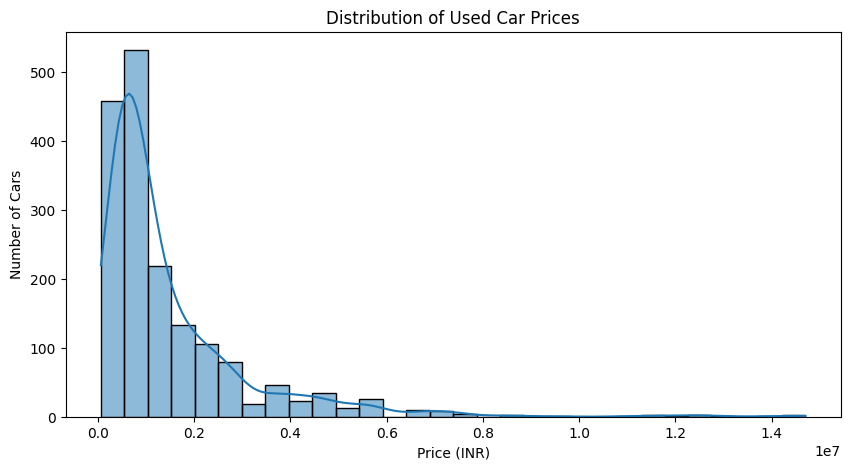

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df_clean['price'], bins=30, kde=True)

plt.title('Distribution of Used Car Prices')
plt.xlabel('Price (INR)')
plt.ylabel('Number of Cars')
plt.show()

Cars by brand

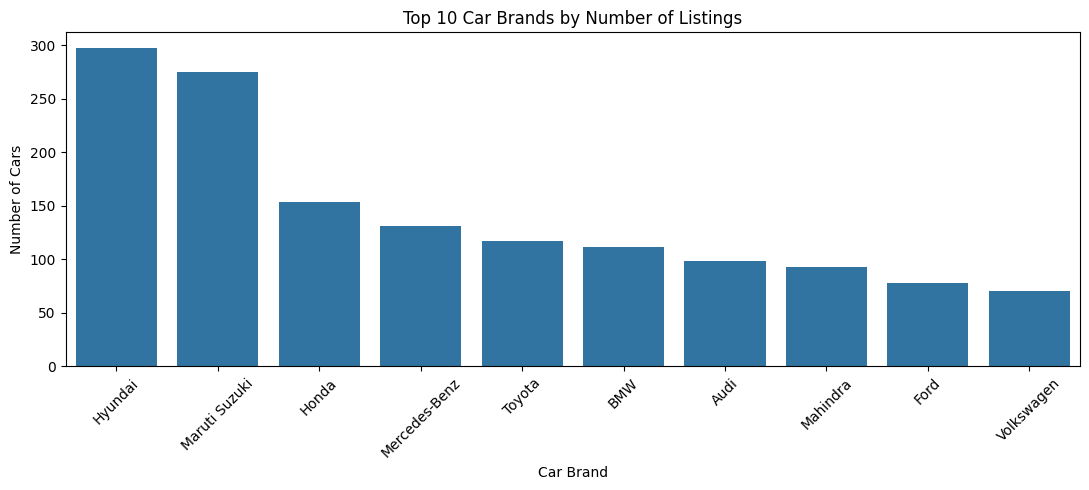

In [18]:
brand_counts = df_clean['brand'].value_counts().head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=brand_counts.index, y=brand_counts.values)

plt.title('Top 10 Car Brands by Number of Listings')
plt.xlabel('Car Brand')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Fuel type distribution

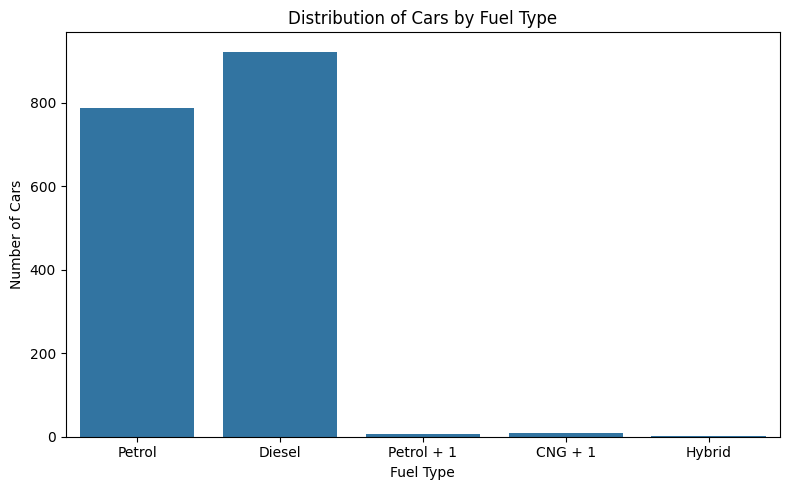

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='fuel_type')

plt.title('Distribution of Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.tight_layout()
plt.show()

Price vs Manufacturing Year

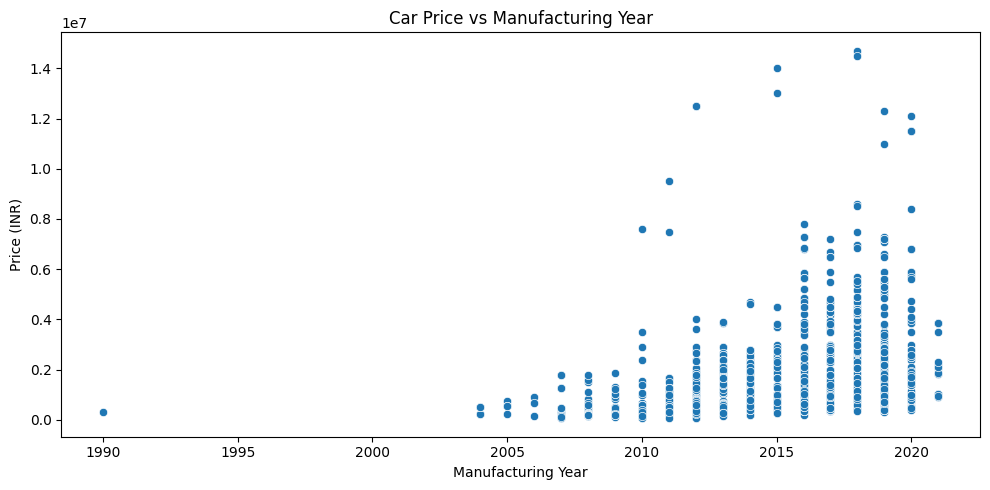

In [20]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df_clean, x='year', y='price')

plt.title('Car Price vs Manufacturing Year')
plt.xlabel('Manufacturing Year')
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

Distance travelled vs Price

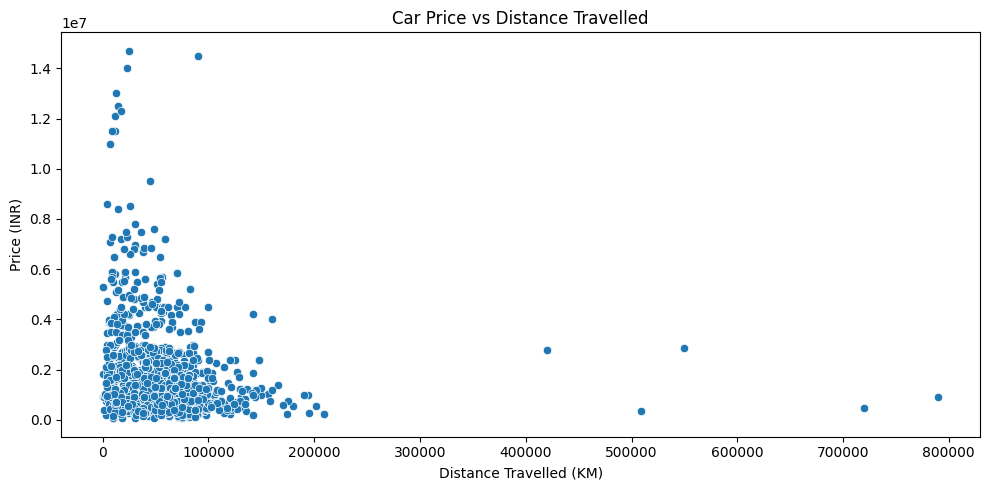

In [21]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df_clean, x='distance_travelled(kms)', y='price')

plt.title('Car Price vs Distance Travelled')
plt.xlabel('Distance Travelled (KM)')
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

Final visualisation – Price by fuel type

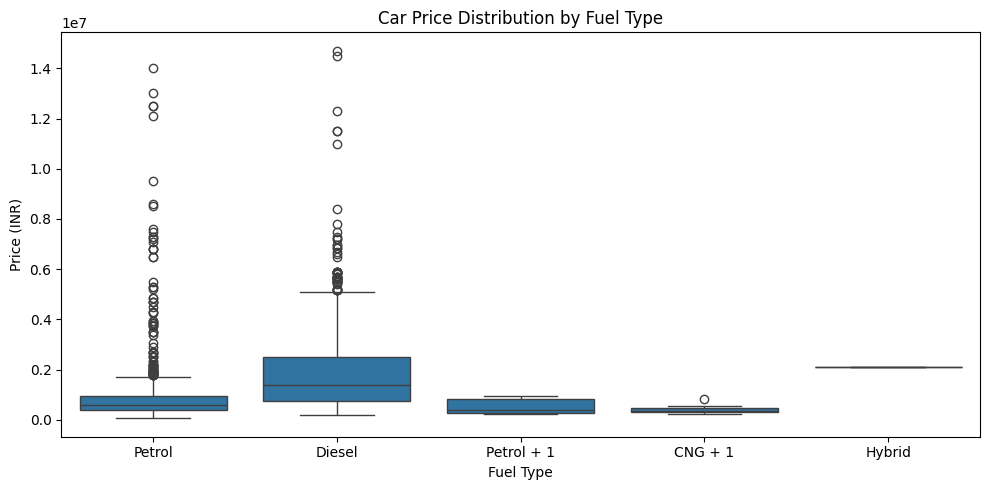

In [22]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_clean, x='fuel_type', y='price')

plt.title('Car Price Distribution by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

Correlation analysis

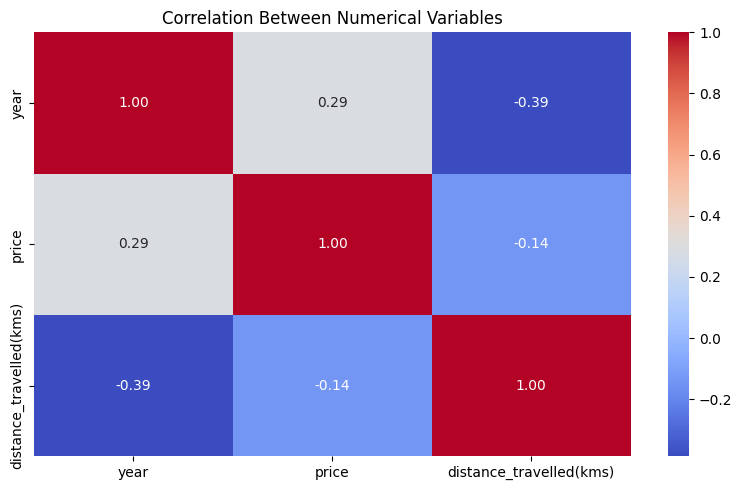

In [23]:
correlation = df_clean[['year', 'price', 'distance_travelled(kms)']].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Between Numerical Variables')
plt.tight_layout()
plt.show()

Outlier detection using IQR

In [24]:
columns = ['price', 'distance_travelled(kms)']

for col in columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print("\nColumn:", col)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Number of Outliers:", len(outliers))


Column: price
Lower Limit: -1375000.0
Upper Limit: 3745000.0
Number of Outliers: 158

Column: distance_travelled(kms)
Lower Limit: -33250.0
Upper Limit: 132750.0
Number of Outliers: 41


Multivariate analysis

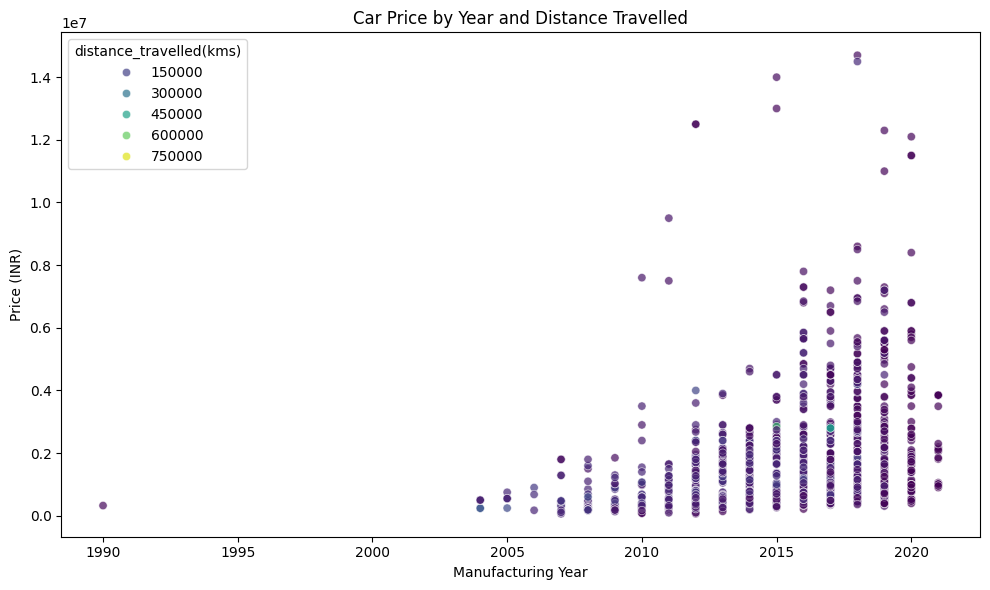

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='year',
    y='price',
    hue='distance_travelled(kms)',
    palette='viridis',
    alpha=0.7
)

plt.title('Car Price by Year and Distance Travelled')
plt.xlabel('Manufacturing Year')
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

outlier detection op

In [26]:
columns = ['price', 'distance_travelled(kms)']

for col in columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print("\nColumn:", col)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Number of Outliers:", len(outliers))


Column: price
Lower Limit: -1375000.0
Upper Limit: 3745000.0
Number of Outliers: 158

Column: distance_travelled(kms)
Lower Limit: -33250.0
Upper Limit: 132750.0
Number of Outliers: 41


so my final five finding would be

In [27]:
print("Top Brand:")
print(df_clean['brand'].value_counts().idxmax())

print("\nMost Common Fuel:")
print(df_clean['fuel_type'].value_counts().idxmax())

print("\nMost Listings City:")
print(df_clean['city'].value_counts().idxmax())

print("\nAverage Price by Fuel Type:")
print(df_clean.groupby('fuel_type')['price'].mean().sort_values(ascending=False))

print("\nAverage Price by Year:")
print(df_clean.groupby('year')['price'].mean().tail(10))

print("\nAverage Distance by Fuel Type:")
print(df_clean.groupby('fuel_type')['distance_travelled(kms)'].mean())

Top Brand:
Hyundai

Most Common Fuel:
Diesel

Most Listings City:
Chennai

Average Price by Fuel Type:
fuel_type
Hybrid        2.100000e+06
Diesel        1.914885e+06
Petrol        1.020832e+06
Petrol + 1    5.300000e+05
CNG + 1       4.218750e+05
Name: price, dtype: float64

Average Price by Year:
year
2012    1.067243e+06
2013    1.074933e+06
2014    1.099261e+06
2015    1.302557e+06
2016    1.488753e+06
2017    1.558636e+06
2018    2.043317e+06
2019    2.145933e+06
2020    2.621862e+06
2021    2.070048e+06
Name: price, dtype: float64

Average Distance by Fuel Type:
fuel_type
CNG + 1       57454.750000
Diesel        63641.559653
Hybrid         3000.000000
Petrol        42426.549492
Petrol + 1    52660.833333
Name: distance_travelled(kms), dtype: float64
